In [1]:
import os
import sys

sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import pandas as pd

from chessstyle import features, fetch, match, profile

USERNAME = os.environ["CHESS_USERNAME"]

In [2]:
games = fetch.games(USERNAME)
engine = features.open_engine()
table = features.features_table(games, USERNAME, engine)
if engine:
    engine.quit()
print(len(games), "rated rapid games;", (table.who == "player").sum(), "analysed (10+ moves)")

2111 rated rapid games; 1989 analysed (10+ moves)


In [3]:
# Style profile: current games vs same-rating peers
z, cur = profile.player_frame(table)
me = z[cur]
vec = me[profile.FEATURES].mean()
print(f"current games: {cur.sum()} (rating {me.rating.min()}–{me.rating.max()})")
for group, fs in profile.GROUPS.items():
    print(f"\n{group}: {vec[fs].mean():+.2f}σ")
    for f in fs:
        print(f"  {f:<20}{vec[f]:+.2f}σ{'  *both players shape this' if f in profile.INTERACTIVE else ''}")

current games: 342 (rating 1629–1870)

Aggression: -0.01σ
  checks              -0.00σ
  captures            -0.09σ
  sacrifices          -0.03σ
  early_queen         +0.07σ

King play: -0.10σ
  castled             +0.35σ
  castle_move         -0.40σ
  castle_long         -0.18σ
  opposite_castle     -0.13σ  *both players shape this
  pawn_storm          -0.12σ

Simplification: +0.05σ
  queen_trade         -0.02σ  *both players shape this
  queen_trade_move    +0.06σ  *both players shape this
  material_30         +0.14σ  *both players shape this
  endgame             +0.09σ  *both players shape this
  game_len            +0.01σ  *both players shape this

Piece preference: -0.14σ
  bishop_takes_knight -0.17σ
  bishop_pair_kept    +0.02σ
  pawn_share          -0.28σ

Time use: +0.48σ
  time_open           +0.48σ
  time_mid            +0.86σ
  time_end            -0.17σ
  time_trouble        +0.77σ


In [4]:
# Openings and material blunders (raw, not z-scored)
mine = table[cur]
print((mine.family + " as " + mine.side).value_counts(normalize=True).head(6).round(2))
peers = table[table.game.isin(mine.game) & (table.who == "opponent")]
print(f"material blunders/game: you {mine.material_blunders.mean():.2f}, peers {peers.material_blunders.mean():.2f}")

french as black       0.32
open as white         0.21
sicilian as white     0.11
d4-other as black     0.08
caro-kann as white    0.06
french as white       0.06
Name: proportion, dtype: float64
material blunders/game: you 0.59, peers 0.51


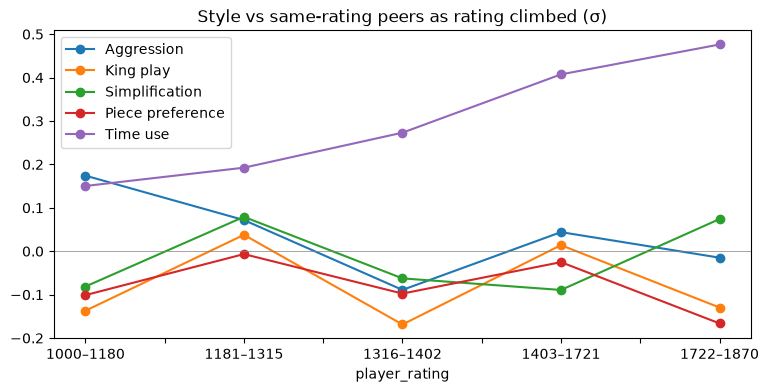

In [5]:
# Climb: style vs same-band peers across rating bands
p = z[(z.who == "player") & z.band.notna()]
labels = table.loc[p.index].groupby(p.band).player_rating.agg(lambda r: f"{r.min()}–{r.max()}")
climb = pd.DataFrame({g: p.groupby("band")[fs].mean().mean(axis=1) for g, fs in profile.GROUPS.items()})
climb.index = labels.loc[climb.index]
climb.plot(marker="o", figsize=(9, 4), title="Style vs same-rating peers as rating climbed (σ)")
plt.axhline(0, color="grey", lw=0.5)
plt.show()

In [6]:
# GM matches with reasons and uncertainty
gm = pd.read_csv(fetch.DATA / "gm_games.csv")
P = profile.vectors(profile.normalise(gm, gm.username.notna()))
boot = match.bootstrap(me, P)
for u, r in boot.head(5).iterrows():
    e = match.explain(vec, P.loc[u])
    print(f"{u:<20} {r.sim:.2f} [{r.lo:.2f}, {r.hi:.2f}]  P(top3)={r.p_top:.0%}  "
          f"shared: {', '.join(e['shared'])}  differs: {e['differs']}")

viditchess           0.80 [0.73, 0.86]  P(top3)=81%  shared: time_mid, time_trouble, castled  differs: pawn_storm
firouzja2003         0.79 [0.74, 0.84]  P(top3)=88%  shared: time_mid, time_trouble, time_open  differs: castle_move
grischuk             0.79 [0.75, 0.83]  P(top3)=87%  shared: time_mid, time_trouble, time_open  differs: bishop_takes_knight
sibelephant          0.75 [0.69, 0.81]  P(top3)=21%  shared: time_mid, time_trouble, time_open  differs: material_30
vincentkeymer        0.74 [0.67, 0.81]  P(top3)=7%  shared: time_mid, time_trouble, pawn_share  differs: castle_move


In [7]:
# Repertoire matches and reading list
fams = (mine.family + "|" + mine.side).value_counts().head(3).index
print((gm.family + "|" + gm.side).isin(fams).groupby(gm.username).mean().nlargest(5).round(2))
for url in match.reading_list(gm, boot.index[0], fams):
    print(url)

username
levonaronian    0.44
szparu          0.38
lyonbeast       0.37
lachesisq       0.37
jospem          0.37
dtype: float64
https://www.chess.com/game/live/168777273629
https://www.chess.com/game/live/168604470035
https://www.chess.com/game/live/168168614027
https://www.chess.com/game/live/141984052423
https://www.chess.com/game/live/133553940051
https://www.chess.com/game/live/133550944667
https://www.chess.com/game/live/133548539107
https://www.chess.com/game/live/121450862167
https://www.chess.com/game/live/121447302607
https://www.chess.com/game/live/121361400029


In [8]:
# Stability: do the two halves of my current games agree?
m = me.sort_values("end_time")
half = len(m) // 2
a = match.similarities(m.iloc[:half][profile.FEATURES].mean(), P).nlargest(5).index
b = match.similarities(m.iloc[half:][profile.FEATURES].mean(), P).nlargest(5).index
print("top-5 overlap between halves:", len(set(a) & set(b)), "/ 5")

top-5 overlap between halves: 4 / 5
